In [9]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd()
if not (ROOT/'data').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from utils.calculations import calculate_all, calculate_strategy, cloud_break_even, fmt
CONFIG=json.loads((ROOT/'data/task_06_tco_config.json').read_text(encoding='utf-8'))
frames, summaries=calculate_all(CONFIG)
be=cloud_break_even(CONFIG)
task_opening=f"""# Экзаменационная задача №{CONFIG['task_id']}. {CONFIG['title']}
**Студент:** {CONFIG['student_name']}  
**Группа:** {CONFIG['group']}  
**Компания:** {CONFIG['company']}  
**Система:** {CONFIG['system_name']}  
**Горизонт анализа:** {CONFIG['horizon_years']} лет  
**Ставка дисконтирования:** {CONFIG['discount_rate']*100:.0f}% годовых

Все исходные параметры хранятся в JSON, а денежные потоки, дисконтирование, графики и выводы рассчитываются ниже по формулам модели."""
display(Markdown(task_opening))

# Экзаменационная задача №6. Расчёт TCO и выбор инфраструктурной стратегии
**Студент:** Кузнецова Дарья Михайловна  
**Группа:** БИ ОЗФО5-1  
**Компания:** ТехноГос  
**Система:** государственный информационный портал  
**Горизонт анализа:** 5 лет  
**Ставка дисконтирования:** 12% годовых

Все исходные параметры хранятся в JSON, а денежные потоки, дисконтирование, графики и выводы рассчитываются ниже по формулам модели.

## Условие задачи

Компания «ТехноГос» рассматривает три варианта ИТ-инфраструктуры для государственного информационного портала на пятилетнем горизонте:

1. **On-premise ЦОД:** оборудование и ПО — 85 млн руб. разово; настройка и интеграция — 12 млн руб.; эксплуатация — 4,5 млн руб./год; персонал — 9 млн руб./год; обновление ПО — 2,5 млн руб./год; обучение — 1,5 млн руб. в первый год; простои и восстановление — 3 млн руб./год; модернизация в третий год — 8 млн руб.
2. **Облачный провайдер IaaS + PaaS:** настройка и миграция — 5 млн руб.; облачные услуги — 16 млн руб./год с ростом 5%; персонал — 4 млн руб./год; поддержка провайдера — 2,5 млн руб./год; обучение — 2 млн руб.
3. **Гибридная стратегия:** оборудование — 35 млн руб.; настройка — 8 млн руб.; облачные услуги — 8 млн руб./год; эксплуатация — 3 млн руб./год; персонал — 6 млн руб./год; поддержка — 2 млн руб./год; модернизация в третий год — 4 млн руб.

Дополнительно: ставка дисконтирования — 12%; налог на имущество On-premise — 2,2% от остаточной стоимости оборудования; амортизация оборудования — линейная, 5 лет. Требуется рассчитать ежегодные потоки, дисконтированный TCO, точку безубыточности, чувствительность и стратегическую рекомендацию.

## Экономическая постановка

**TCO (Total Cost of Ownership)** — совокупная стоимость владения инфраструктурой за весь горизонт. В этой задаче учитываются не только первоначальные затраты, но и ежегодная эксплуатация, персонал, поддержка, обновления, простои, налог на имущество и модернизация.

Для сравнения вариантов используется дисконтированный TCO: затраты в будущих годах приводятся к стоимости на начало проекта. Это важно, потому что рубль сегодня экономически ценнее рубля через несколько лет.

Формула дисконтирования:

`PV_t = CF_t / (1 + r)^t`,

где `CF_t` — денежный поток в году `t`, `r` — ставка дисконтирования, `t=0` — момент начала проекта.

## Шаг 1. Исходные параметры и налог на имущество

Значения ниже загружаются из JSON. Налог рассчитан корректно для линейной амортизации: за каждый год берётся 2,2% от **средней остаточной стоимости** оборудования в начале и конце года. Например, для On-premise в первый год средняя стоимость равна `(85 + 68) / 2 = 76,5 млн руб.`, поэтому налог равен `76,5 × 2,2% = 1,683 млн руб.`. Налог не начисляется в момент `t=0` и уменьшается по мере амортизации.

In [10]:
parameter_names={
    'equipment':'Оборудование', 'setup':'Настройка/миграция', 'training':'Обучение',
    'operations':'Эксплуатация', 'personnel':'Персонал', 'software_updates':'Обновление ПО',
    'downtime_recovery':'Простои и восстановление', 'cloud_services':'Облачные услуги',
    'provider_support':'Поддержка провайдера', 'support':'Поддержка',
    'modernization':'Модернизация'
}
input_rows=[]
for key in ['on_premise','cloud','hybrid']:
    d=CONFIG[key]
    for field,value in d['one_time'].items():
        input_rows.append({'Вариант':d['name'],'Категория':'Разово','Параметр':parameter_names.get(field,field),'Значение (млн руб. или %)':fmt(value)})
    for field,value in d['annual'].items():
        suffix='в год'
        input_rows.append({'Вариант':d['name'],'Категория':suffix,'Параметр':parameter_names.get(field,field),'Значение (млн руб. или %)':fmt(value)})
    if 'cloud_growth_rate' in d:
        input_rows.append({'Вариант':d['name'],'Категория':'Дополнительно','Параметр':'Рост облачных услуг','Значение (млн руб. или %)':f"{d['cloud_growth_rate']*100:.0f}% в год"})
    if d.get('modernization',{}).get('amount',0):
        input_rows.append({'Вариант':d['name'],'Категория':f"Год {d['modernization']['year']}",'Параметр':'Модернизация','Значение (млн руб. или %)':fmt(d['modernization']['amount'])})
display(pd.DataFrame(input_rows).fillna(''))
print(f"Налоговая база: {CONFIG['modeling_choices']['property_tax_basis_label']}.")

,Вариант,Категория,Параметр,Значение (млн руб. или %)
0,On-premise ЦОД,Разово,Оборудование,"85,00"
1,On-premise ЦОД,Разово,Настройка/миграция,"12,00"
2,On-premise ЦОД,Разово,Обучение,"1,50"
3,On-premise ЦОД,в год,Эксплуатация,"4,50"
4,On-premise ЦОД,в год,Персонал,"9,00"
5,On-premise ЦОД,в год,Обновление ПО,"2,50"
6,On-premise ЦОД,в год,Простои и восстановление,"3,00"
7,On-premise ЦОД,Год 3,Модернизация,"8,00"
8,Облачный провайдер (IaaS + PaaS),Разово,setup_migration,"5,00"
9,Облачный провайдер (IaaS + PaaS),Разово,Обучение,"2,00"


Налоговая база: Средняя остаточная стоимость оборудования за соответствующий год.


## Шаг 2. Ежегодные денежные потоки

Каждая строка показывает, сколько денег фактически требуется в конкретном году. Год 0 содержит разовые затраты. В последующие годы добавляются регулярные расходы, рост стоимости облачных услуг, налог и модернизация в третий год.

In [11]:
for key,frame in frames.items():
    print(f"\n{frame['strategy'].iloc[0]}")
    show=frame[['year','capex','setup','training','recurring','modernization','property_tax','nominal_cost']].copy()
    show.columns=['Год','Оборудование','Настройка','Обучение','Регулярные затраты','Модернизация','Налог','Итого за год']
    for col in show.columns[1:]: show[col]=show[col].map(lambda x: fmt(x,3))
    display(show)
# Динамическое пояснение к таблицам денежных потоков.
print('Что видно из таблиц денежных потоков:')
for key,frame in frames.items():
    strategy=frame['strategy'].iloc[0]
    peak=frame.loc[frame['nominal_cost'].idxmax()]
    final=frame.iloc[-1]
    print(f"• «{strategy}»: максимальные затраты приходятся на год {int(peak['year'])} и составляют {fmt(peak['nominal_cost'])} млн руб.; затраты последнего года — {fmt(final['nominal_cost'])} млн руб.")
modernization_rows=[(frame['strategy'].iloc[0],int(row['year']),row['modernization']) for frame in frames.values() for _,row in frame.iterrows() if row['modernization']>0]
if modernization_rows:
    print('• Отдельные пики в таблицах связаны с разовой модернизацией: ' + '; '.join(f"«{name}», год {year} — {fmt(amount)} млн руб." for name,year,amount in modernization_rows) + '.')
print('• Строка «Итого за год» складывает регулярные расходы, разовые мероприятия и налог, поэтому именно её используют для последующего дисконтирования.')



On-premise ЦОД


,Год,Оборудование,Настройка,Обучение,Регулярные затраты,Модернизация,Налог,Итого за год
0,0,"85,000","13,500","1,500","0,000","0,000","0,000","98,500"
1,1,"0,000","0,000","0,000","19,000","0,000","1,683","20,683"
2,2,"0,000","0,000","0,000","19,000","0,000","1,309","20,309"
3,3,"0,000","0,000","0,000","19,000","8,000","0,935","27,935"
4,4,"0,000","0,000","0,000","19,000","0,000","0,561","19,561"
5,5,"0,000","0,000","0,000","19,000","0,000","0,187","19,187"



Облачный провайдер (IaaS + PaaS)


,Год,Оборудование,Настройка,Обучение,Регулярные затраты,Модернизация,Налог,Итого за год
0,0,"0,000","7,000","2,000","0,000","0,000","0,000","7,000"
1,1,"0,000","0,000","0,000","22,500","0,000","0,000","22,500"
2,2,"0,000","0,000","0,000","23,300","0,000","0,000","23,300"
3,3,"0,000","0,000","0,000","24,140","0,000","0,000","24,140"
4,4,"0,000","0,000","0,000","25,022","0,000","0,000","25,022"
5,5,"0,000","0,000","0,000","25,948","0,000","0,000","25,948"



Гибридная стратегия


,Год,Оборудование,Настройка,Обучение,Регулярные затраты,Модернизация,Налог,Итого за год
0,0,"35,000","8,000","0,000","0,000","0,000","0,000","43,000"
1,1,"0,000","0,000","0,000","19,000","0,000","0,693","19,693"
2,2,"0,000","0,000","0,000","19,000","0,000","0,539","19,539"
3,3,"0,000","0,000","0,000","19,000","4,000","0,385","23,385"
4,4,"0,000","0,000","0,000","19,000","0,000","0,231","19,231"
5,5,"0,000","0,000","0,000","19,000","0,000","0,077","19,077"


Что видно из таблиц денежных потоков:
• «On-premise ЦОД»: максимальные затраты приходятся на год 0 и составляют 98,50 млн руб.; затраты последнего года — 19,19 млн руб.
• «Облачный провайдер (IaaS + PaaS)»: максимальные затраты приходятся на год 5 и составляют 25,95 млн руб.; затраты последнего года — 25,95 млн руб.
• «Гибридная стратегия»: максимальные затраты приходятся на год 0 и составляют 43,00 млн руб.; затраты последнего года — 19,08 млн руб.
• Отдельные пики в таблицах связаны с разовой модернизацией: «On-premise ЦОД», год 3 — 8,00 млн руб.; «Гибридная стратегия», год 3 — 4,00 млн руб..
• Строка «Итого за год» складывает регулярные расходы, разовые мероприятия и налог, поэтому именно её используют для последующего дисконтирования.


## Шаг 3. Дисконтированный TCO

Суммарный номинальный TCO — простая сумма затрат. Дисконтированный TCO — сумма приведённых к году 0 затрат. Для года 0 коэффициент равен 1, для года 1 — `1/(1+r)`, для года 5 — `1/(1+r)^5`. Именно дисконтированный показатель используется для выбора стратегии.

In [12]:
result=summaries.copy()
result['Номинальный TCO, млн руб.']=result.pop('nominal_tco').map(lambda x: fmt(x,2))
result['Дисконтированный TCO, млн руб.']=result.pop('discounted_tco').map(lambda x: fmt(x,2))
result['Начальные затраты, млн руб.']=result.pop('initial_cost').map(lambda x: fmt(x,2))
result.columns=['Стратегия','Номинальный TCO, млн руб.','Дисконтированный TCO, млн руб.','Начальные затраты, млн руб.']
display(result)
best=summaries.iloc[0]
print(f"Минимальный дисконтированный TCO: {best['strategy']} — {fmt(best['discounted_tco'])} млн руб.")
second=summaries.iloc[1]
savings=second['discounted_tco']-best['discounted_tco']
initial_best=summaries.loc[summaries['initial_cost'].idxmin()]
print('Что видно из таблицы TCO:')
print(f"• По итоговому дисконтированному TCO лидирует «{best['strategy']}»: {fmt(best['discounted_tco'])} млн руб.")
print(f"• Преимущество над ближайшей альтернативой «{second['strategy']}» составляет {fmt(savings)} млн руб.")
print(f"• Минимальные начальные затраты также у «{initial_best['strategy']}»: {fmt(initial_best['initial_cost'])} млн руб.")
print('• Для выбора на полном горизонте важнее дисконтированный TCO, а не только разовые затраты в нулевом году.')


,Стратегия,"Номинальный TCO, млн руб.","Дисконтированный TCO, млн руб.","Начальные затраты, млн руб."
0,Облачный провайдер (IaaS + PaaS),"127,91","93,47","7,00"
1,Гибридная стратегия,"143,93","115,85","43,00"
2,On-premise ЦОД,"206,18","176,36","98,50"


Минимальный дисконтированный TCO: Облачный провайдер (IaaS + PaaS) — 93,47 млн руб.
Что видно из таблицы TCO:
• По итоговому дисконтированному TCO лидирует «Облачный провайдер (IaaS + PaaS)»: 93,47 млн руб.
• Преимущество над ближайшей альтернативой «Гибридная стратегия» составляет 22,38 млн руб.
• Минимальные начальные затраты также у «Облачный провайдер (IaaS + PaaS)»: 7,00 млн руб.
• Для выбора на полном горизонте важнее дисконтированный TCO, а не только разовые затраты в нулевом году.


## Шаг 4. Точка безубыточности On-premise и облака

Точка безубыточности по годам существует, если накопленные дисконтированные затраты двух стратегий сравнялись или одна стратегия стала дешевле другой. Дополнительно рассчитывается пороговая базовая стоимость облачных услуг, при которой облако сравнялось бы с On-premise на всём пятилетнем горизонте при прочих неизменных параметрах.

In [13]:
be_table=pd.DataFrame({'Год':frames['on_premise']['year'],'Накопленный PV On-premise, млн руб.':frames['on_premise']['cumulative_discounted_cost'].map(lambda x:fmt(x,2)),'Накопленный PV Облако, млн руб.':frames['cloud']['cumulative_discounted_cost'].map(lambda x:fmt(x,2)),'Разница On-premise − Облако, млн руб.':(frames['on_premise']['cumulative_discounted_cost']-frames['cloud']['cumulative_discounted_cost']).map(lambda x:fmt(x,2))})
display(be_table)
cross=None
for _,row in be_table.iterrows():
    if float(str(row['Разница On-premise − Облако, млн руб.']).replace(' ','').replace(',','.'))<=0: cross=row['Год']; break
print(f"Точка пересечения накопленных затрат: {cross if cross is not None else 'не достигается на горизонте анализа'}.")
print(f"Пороговая базовая стоимость облачных услуг: {fmt(be['cloud_base_annual_break_even'])} млн руб./год при прочих неизменных параметрах.")

,Год,"Накопленный PV On-premise, млн руб.","Накопленный PV Облако, млн руб.","Разница On-premise − Облако, млн руб."
0,0,"98,50","7,00","91,50"
1,1,"116,97","27,09","89,88"
2,2,"133,16","45,66","87,49"
3,3,"153,04","62,85","90,19"
4,4,"165,47","78,75","86,72"
5,5,"176,36","93,47","82,89"


Точка пересечения накопленных затрат: не достигается на горизонте анализа.
Пороговая базовая стоимость облачных услуг: 37,04 млн руб./год при прочих неизменных параметрах.


## Шаг 5. График накопленных дисконтированных затрат

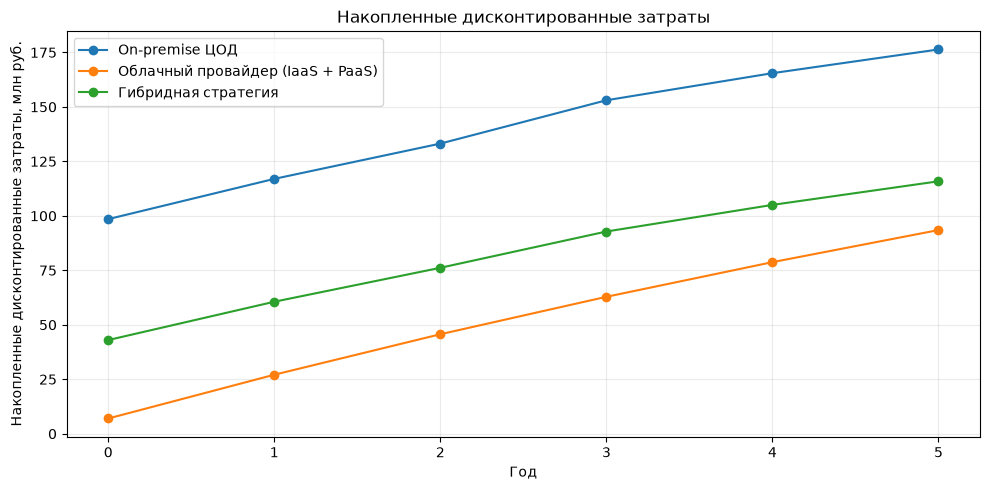

Что показывает график:
• В начале проекта минимальные разовые затраты у стратегии «Облачный провайдер (IaaS + PaaS)»: 7,00 млн руб.
• К концу горизонта анализа минимальные накопленные дисконтированные затраты у стратегии «Облачный провайдер (IaaS + PaaS)»: 93,47 млн руб.
• На всём горизонте анализа лидирует стратегия «Облачный провайдер (IaaS + PaaS)»: её линия остаётся ниже остальных.
• Линии не пересекаются на заданном горизонте: относительный порядок затрат сохраняется.
• Экономический смысл: чем ниже линия, тем меньше накопленные затраты к соответствующему году. Для выбора на полном горизонте используется итоговое значение «Облачный провайдер (IaaS + PaaS)».


In [14]:
plt.figure(figsize=(10,5))
for key,frame in frames.items(): plt.plot(frame['year'],frame['cumulative_discounted_cost'],marker='o',label=frame['strategy'].iloc[0])
plt.xlabel('Год'); plt.ylabel('Накопленные дисконтированные затраты, млн руб.'); plt.title('Накопленные дисконтированные затраты'); plt.grid(alpha=.25); plt.legend(); plt.tight_layout(); plt.show()
# Автоматическая интерпретация графика по рассчитанным данным.
initial_costs={key:frame.loc[frame['year']==0,'nominal_cost'].iloc[0] for key,frame in frames.items()}
final_costs={key:frame['cumulative_discounted_cost'].iloc[-1] for key,frame in frames.items()}
initial_best=min(initial_costs,key=initial_costs.get)
final_best=min(final_costs,key=final_costs.get)
strategies={key:frame['strategy'].iloc[0] for key,frame in frames.items()}
ordered_by_year=[]
for year in frames['on_premise']['year']:
    year_costs={key:frame.loc[frame['year']==year,'cumulative_discounted_cost'].iloc[0] for key,frame in frames.items()}
    ordered_by_year.append(min(year_costs,key=year_costs.get))
stable_leader=len(set(ordered_by_year))==1
print('Что показывает график:')
print(f"• В начале проекта минимальные разовые затраты у стратегии «{strategies[initial_best]}»: {fmt(initial_costs[initial_best])} млн руб.")
print(f"• К концу горизонта анализа минимальные накопленные дисконтированные затраты у стратегии «{strategies[final_best]}»: {fmt(final_costs[final_best])} млн руб.")
if stable_leader:
    print(f"• На всём горизонте анализа лидирует стратегия «{strategies[ordered_by_year[0]]}»: её линия остаётся ниже остальных.")
else:
    changes=[]
    for prev,cur in zip(ordered_by_year,ordered_by_year[1:]):
        if prev != cur:
            changes.append(f"«{strategies[prev]}» → «{strategies[cur]}»")
    print(f"• Лидер меняется по годам: {'; '.join(changes)}. Поэтому результат зависит от продолжительности эксплуатации.")
# Проверяем пересечение линий через знак разницы между каждой парой стратегий.
cross_pairs=[]
keys=list(frames)
for i,left in enumerate(keys):
    for right in keys[i+1:]:
        diff=frames[left]['cumulative_discounted_cost'].to_numpy()-frames[right]['cumulative_discounted_cost'].to_numpy()
        if (diff[:-1]*diff[1:]<0).any() or (diff==0).any():
            cross_pairs.append(f"«{strategies[left]}» и «{strategies[right]}»")
if cross_pairs:
    print(f"• Обнаружено пересечение или совпадение линий для пар: {', '.join(cross_pairs)}.")
else:
    print('• Линии не пересекаются на заданном горизонте: относительный порядок затрат сохраняется.')
print(f"• Экономический смысл: чем ниже линия, тем меньше накопленные затраты к соответствующему году. Для выбора на полном горизонте используется итоговое значение «{strategies[final_best]}».")


## Шаг 6. Анализ чувствительности

Проверяем, сохраняется ли выбор при изменении ставки дисконтирования и стоимости облачных услуг. Если лидер не меняется, рекомендация устойчива к соответствующему изменению параметра.

In [15]:
rate_rows=[]
for rate in CONFIG['sensitivity']['discount_rates']:
    _,tab=calculate_all(CONFIG,discount_rate=rate)
    row={'Ставка':f'{rate*100:.0f}%'}
    for _,r in tab.iterrows(): row[r['strategy']]=r['discounted_tco']
    rate_rows.append(row)
rate_df=pd.DataFrame(rate_rows)
for col in rate_df.columns[1:]: rate_df[col]=rate_df[col].map(lambda x:fmt(x,2))
display(rate_df)
cloud_rows=[]
for mult in CONFIG['sensitivity']['cloud_cost_multipliers']:
    _,tab=calculate_all(CONFIG,cloud_multiplier=mult)
    row={'Изменение облачных услуг':f'{(mult-1)*100:+.0f}%'}
    for _,r in tab.iterrows(): row[r['strategy']]=r['discounted_tco']
    cloud_rows.append(row)
cloud_df=pd.DataFrame(cloud_rows)
for col in cloud_df.columns[1:]: cloud_df[col]=cloud_df[col].map(lambda x:fmt(x,2))
display(cloud_df)
rate_raw=[]
for rate in CONFIG['sensitivity']['discount_rates']:
    _,tab=calculate_all(CONFIG,discount_rate=rate)
    rate_raw.append((rate,tab.iloc[0]['strategy'],tab.iloc[0]['discounted_tco']))
cloud_raw=[]
for mult in CONFIG['sensitivity']['cloud_cost_multipliers']:
    _,tab=calculate_all(CONFIG,cloud_multiplier=mult)
    cloud_raw.append((mult,tab.iloc[0]['strategy'],tab.iloc[0]['discounted_tco']))
print('Что видно из таблиц чувствительности:')
if len(set(row[1] for row in rate_raw))==1:
    print(f"• При всех проверенных ставках дисконтирования лидирует «{rate_raw[0][1]}», поэтому выбор устойчив к этому параметру.")
else:
    print('• При изменении ставки дисконтирования лидер меняется, поэтому выбор зависит от оценки стоимости денег во времени.')
if len(set(row[1] for row in cloud_raw))==1:
    print(f"• При всех проверенных изменениях стоимости облачных услуг лидирует «{cloud_raw[0][1]}».")
else:
    print('• При изменении стоимости облачных услуг лидер меняется; необходимо ориентироваться на фактический тариф и условия контракта.')


,Ставка,Облачный провайдер (IaaS + PaaS),Гибридная стратегия,On-premise ЦОД
0,8%,"103,02","123,67","184,67"
1,12%,"93,47","115,85","176,36"
2,16%,"85,35","109,18","169,26"


,Изменение облачных услуг,Облачный провайдер (IaaS + PaaS),Гибридная стратегия,On-premise ЦОД
0,-20%,"80,86","115,85","176,36"
1,+0%,"93,47","115,85","176,36"
2,+20%,"106,08","115,85","176,36"


Что видно из таблиц чувствительности:
• При всех проверенных ставках дисконтирования лидирует «Облачный провайдер (IaaS + PaaS)», поэтому выбор устойчив к этому параметру.
• При всех проверенных изменениях стоимости облачных услуг лидирует «Облачный провайдер (IaaS + PaaS)».


## Итоговый вывод и стратегическая рекомендация

Выбор делается по минимальному дисконтированному TCO, но окончательное решение также зависит от безопасности, локализации данных, требований ФЗ-152, доступности команды, SLA, масштабируемости, зависимости от поставщика и горизонта эксплуатации. Экономический расчёт показывает стоимость владения, а не автоматически доказывает, что один вариант допустим юридически или технологически.

In [16]:
best_name=best['strategy']; best_cost=best['discounted_tco']; cloud_cost=summaries.loc[summaries['strategy']==CONFIG['cloud']['name'],'discounted_tco'].iloc[0]
print(f"Рекомендуемая стратегия по TCO: {best_name}.")
print(f"Её дисконтированный TCO: {fmt(best_cost)} млн руб.")
print(f"Экономия относительно On-premise: {fmt(summaries.loc[summaries['strategy']==CONFIG['on_premise']['name'],'discounted_tco'].iloc[0]-best_cost)} млн руб.")
print(f"Облако остаётся дешевле On-premise при изменении его цены на +20%: {fmt(cloud_cost)} млн руб. против {fmt(summaries.loc[summaries['strategy']==CONFIG['on_premise']['name'],'discounted_tco'].iloc[0])} млн руб.")
print('Перед заключением контракта проверить требования к локализации и защите данных, SLA, резервированию, условия изменения цены и план выхода из облака.')

Рекомендуемая стратегия по TCO: Облачный провайдер (IaaS + PaaS).
Её дисконтированный TCO: 93,47 млн руб.
Экономия относительно On-premise: 82,89 млн руб.
Облако остаётся дешевле On-premise при изменении его цены на +20%: 93,47 млн руб. против 176,36 млн руб.
Перед заключением контракта проверить требования к локализации и защите данных, SLA, резервированию, условия изменения цены и план выхода из облака.


In [17]:
%%capture
# Экспорт выполненного Notebook в HTML-отчёт
!python -m jupyter nbconvert --to html --no-input --output-dir ../reports --output task_06_report task_06_tco.ipynb